## STATISTICAL ANALYSIS AND HYPOTHESIS TESTING

### 1. IMPORT REQUIRED LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    pearsonr,
    spearmanr,
    ttest_ind,
    chi2_contingency,
    shapiro,
    levene,
    kruskal)

import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan

import warnings
warnings.filterwarnings("ignore")

### 2.Load data set

In [2]:
df=pd.read_csv("8.supermarket.csv")
df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


In [3]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [5]:
df.tail()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976
8522,DRG01,14.800,Low Fat,0.044878,Soft Drinks,75.4670,OUT046,1997,Small,Tier 1,Supermarket Type1,765.6700


In [6]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [7]:
df.shape

(8523, 12)

In [8]:
df.dtypes

Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
dtype: object

In [9]:
df.columns

Index(['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility',
       'Item_Type', 'Item_MRP', 'Outlet_Identifier',
       'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type',
       'Outlet_Type', 'Item_Outlet_Sales'],
      dtype='object')

### Data cleaning

In [10]:
df.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
# Create a copy
data = df.copy()

In [13]:
# Remove duplicate rows
data = data.drop_duplicates()

In [14]:
# Correct inconsistent category names
data["Item_Fat_Content"] = data["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

In [15]:
# Fill missing numerical values with median
data["Item_Weight"] = data["Item_Weight"].fillna(
    data["Item_Weight"].median()
)

In [16]:
# Fill missing categorical values with mode
data["Outlet_Size"] = data["Outlet_Size"].fillna(
    data["Outlet_Size"].mode()[0]
)

In [17]:
data.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [18]:
data.shape

(8523, 12)

### EDA

In [19]:
data.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.00000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.81342,0.066132,140.992782,1997.831867,2181.288914
std,4.22724,0.051598,62.275067,8.371760,1706.499616
min,4.55500,0.000000,31.290000,1985.000000,33.290000
25%,9.31000,0.026989,93.826500,1987.000000,834.247400
50%,12.60000,0.053931,143.012800,1999.000000,1794.331000
75%,16.00000,0.094585,185.643700,2004.000000,3101.296400
max,21.35000,0.328391,266.888400,2009.000000,13086.964800


In [20]:
data["Item_Outlet_Sales"].sum()

np.float64(18591125.4104)

In [21]:
data["Item_Outlet_Sales"].mean()

np.float64(2181.288913575032)

In [22]:
data["Item_Outlet_Sales"].median()

1794.331

In [23]:
data["Item_Outlet_Sales"].std()

1706.499615733832

In [24]:
data["Item_Outlet_Sales"].min()

33.29

In [25]:
data["Item_Outlet_Sales"].max()

13086.9648

In [26]:
# Average sales by outlet type
print("\nAverage Sales by Outlet Type:")

print(
    data.groupby("Outlet_Type")["Item_Outlet_Sales"]
    .agg(["count", "mean", "median", "std"])
)


Average Sales by Outlet Type:
                   count         mean     median          std
Outlet_Type                                                  
Grocery Store       1083   339.828500   256.9988   260.851582
Supermarket Type1   5577  2316.181148  1990.7420  1515.965558
Supermarket Type2    928  1995.498739  1655.1788  1375.932889
Supermarket Type3    935  3694.038558  3364.9532  2127.760054


In [27]:
# Sales by item type
print("\nTotal Sales by Item Type:")

print(
    data.groupby("Item_Type")["Item_Outlet_Sales"]
    .sum()
    .sort_values(ascending=False)
)


Total Sales by Item Type:
Item_Type
Fruits and Vegetables    2.820060e+06
Snack Foods              2.732786e+06
Household                2.055494e+06
Frozen Foods             1.825735e+06
Dairy                    1.522594e+06
Canned                   1.444151e+06
Baking Goods             1.265525e+06
Health and Hygiene       1.045200e+06
Meat                     9.175656e+05
Soft Drinks              8.928977e+05
Breads                   5.532372e+05
Hard Drinks              4.577934e+05
Starchy Foods            3.514013e+05
Others                   3.255176e+05
Breakfast                2.322990e+05
Seafood                  1.488682e+05
Name: Item_Outlet_Sales, dtype: float64


### Visualization

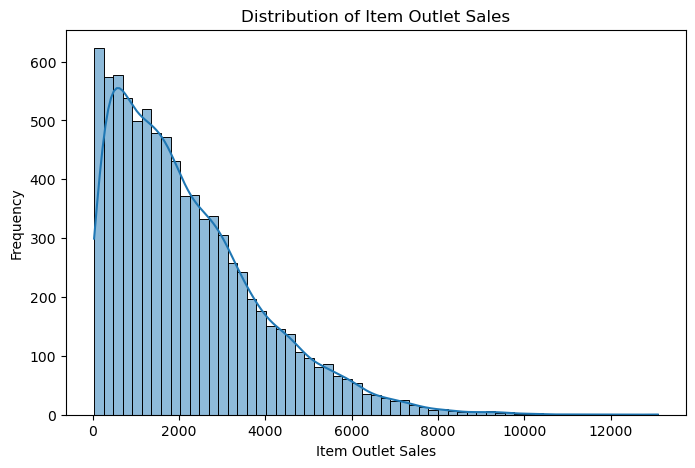

In [28]:
# Sales distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data["Item_Outlet_Sales"],
    kde=True
)

plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Frequency")
plt.show()

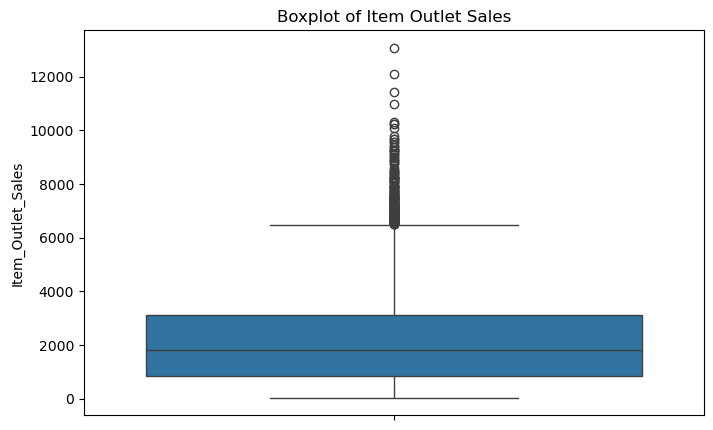

In [29]:
# Boxplot of sales

plt.figure(figsize=(8, 5))

sns.boxplot(
    y=data["Item_Outlet_Sales"]
)

plt.title("Boxplot of Item Outlet Sales")
plt.show()

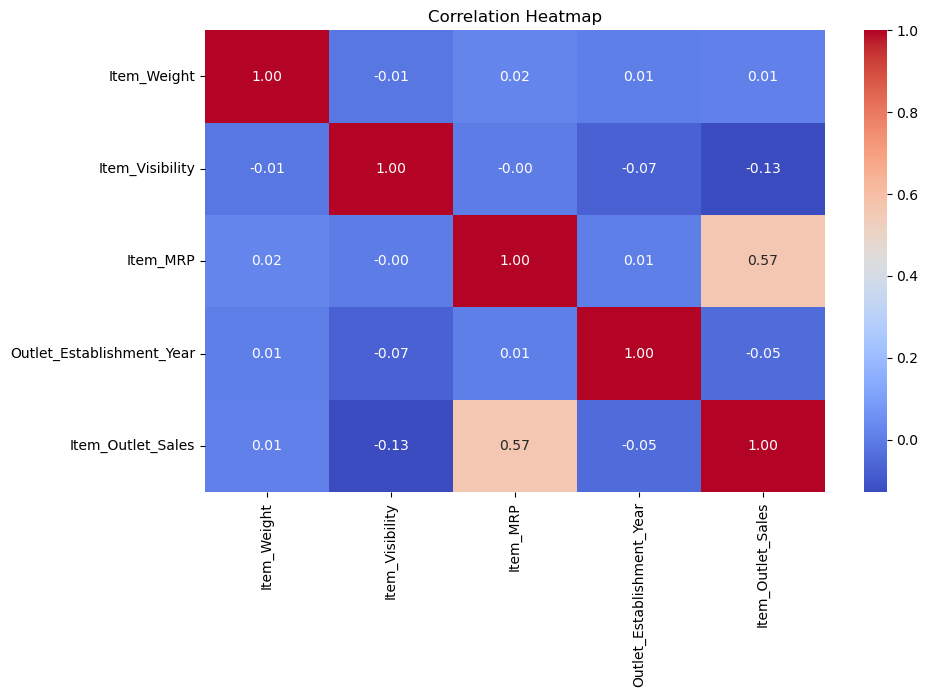

In [30]:
# Correlation heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## HYPOTHESIS TESTING

### TEST 1: PEARSON CORRELATION

In [31]:
# Research Question:
# Is there a significant relationship between Item MRP
# and Item Outlet Sales?

# H0: There is no significant correlation between MRP and Sales.
# H1: There is a significant correlation between MRP and Sales.

In [32]:
print("\n======================================")
print("TEST 1: PEARSON CORRELATION")
print("======================================")

r, p_value = pearsonr(
    data["Item_MRP"],
    data["Item_Outlet_Sales"]
)

print("Pearson Correlation:", r)
print("P-value:", p_value)


TEST 1: PEARSON CORRELATION
Pearson Correlation: 0.5675744466569193
P-value: 0.0


In [33]:
alpha = 0.05

In [34]:
# Confidence interval using Fisher transformation

n = len(data)
z = np.arctanh(r)
se = 1 / np.sqrt(n - 3)

z_critical = stats.norm.ppf(1 - alpha / 2)

lower = np.tanh(z - z_critical * se)
upper = np.tanh(z + z_critical * se)

print("95% Confidence Interval:", (lower, upper))

95% Confidence Interval: (np.float64(0.5530075320357652), np.float64(0.5817944795058714))


In [35]:
# Spearman correlation as an additional check

rho, spearman_p = spearmanr(
    data["Item_MRP"],
    data["Item_Outlet_Sales"]
)

print("Spearman Correlation:", rho)
print("Spearman P-value:", spearman_p)

if p_value < alpha:
    print("Result: Reject Null Hypothesis.")
    print("There is a statistically significant correlation.")
else:
    print("Result: Fail to Reject Null Hypothesis.")
    print("There is no statistically significant correlation.")

Spearman Correlation: 0.5629864415335609
Spearman P-value: 0.0
Result: Reject Null Hypothesis.
There is a statistically significant correlation.


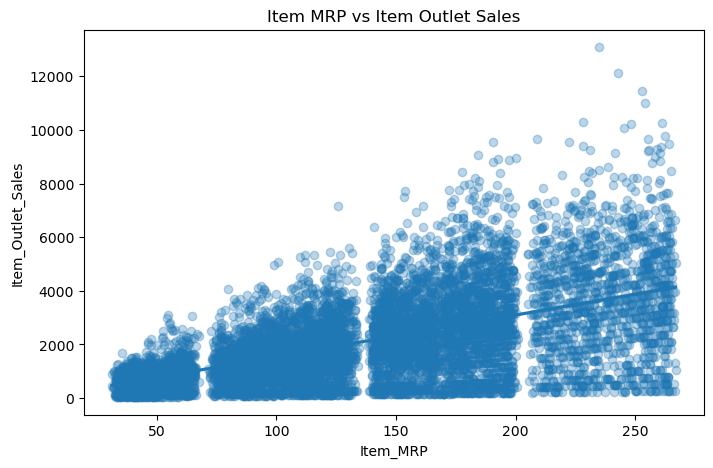

In [36]:
# Visualization

plt.figure(figsize=(8, 5))

sns.regplot(
    x="Item_MRP",
    y="Item_Outlet_Sales",
    data=data,
    scatter_kws={"alpha": 0.3}
)

plt.title("Item MRP vs Item Outlet Sales")
plt.show()

### TEST 2: INDEPENDENT SAMPLES T-TEST

In [37]:
# Research Question:
# Is there a significant difference in average sales
# between Supermarket Type1 and Grocery Store?

# H0: Both outlet types have equal average sales.
# H1: Both outlet types have different average sales.

In [38]:
print("\n======================================")
print("TEST 2: INDEPENDENT SAMPLES T-TEST")
print("======================================")

group1 = data[
    data["Outlet_Type"] == "Supermarket Type1"
]["Item_Outlet_Sales"]

group2 = data[
    data["Outlet_Type"] == "Grocery Store"
]["Item_Outlet_Sales"]

print("Supermarket Type1 Mean:", group1.mean())
print("Grocery Store Mean:", group2.mean())

print("Supermarket Type1 Count:", len(group1))
print("Grocery Store Count:", len(group2))


TEST 2: INDEPENDENT SAMPLES T-TEST
Supermarket Type1 Mean: 2316.181148108302
Grocery Store Mean: 339.8285004616805
Supermarket Type1 Count: 5577
Grocery Store Count: 1083


In [39]:
# Normality checks (Shapiro test on a sample)
print("\nNormality Check:")

for name, group in [
    ("Supermarket Type1", group1),
    ("Grocery Store", group2)
]:
    sample = group.sample(min(5000, len(group)),random_state=42)
    stat, p = shapiro(sample)
    print(name, "Shapiro P-value:", p)


Normality Check:
Supermarket Type1 Shapiro P-value: 2.178063282782179e-44
Grocery Store Shapiro P-value: 6.83171458370908e-30


In [40]:
# Variance equality check

lev_stat, lev_p = levene(
    group1,
    group2,
    center="median")

print("\nLevene Test P-value:", lev_p)


Levene Test P-value: 1.4154562788915513e-209


In [41]:
# Welch's independent t-test
# Does not assume equal variances.

t_stat, p_value = ttest_ind(
    group1,
    group2,
    equal_var=False)

print("\nT-statistic:", t_stat)
print("P-value:", p_value)


T-statistic: 90.69030728312184
P-value: 0.0


In [42]:
# Mean difference and 95% confidence interval

mean_diff = group1.mean() - group2.mean()

se_diff = np.sqrt(
    group1.var(ddof=1) / len(group1)
    +
    group2.var(ddof=1) / len(group2)
)

df_welch = (
    group1.var(ddof=1) / len(group1)
    +
    group2.var(ddof=1) / len(group2)
) ** 2 / (
    (group1.var(ddof=1) / len(group1)) ** 2
    / (len(group1) - 1)
    +
    (group2.var(ddof=1) / len(group2)) ** 2
    / (len(group2) - 1)
)

t_critical = stats.t.ppf(1 - alpha / 2,df_welch)

ci_lower = mean_diff - t_critical * se_diff
ci_upper = mean_diff + t_critical * se_diff

print("Mean Difference:", mean_diff)

print("95% Confidence Interval:",(ci_lower, ci_upper))

Mean Difference: 1976.3526476466213
95% Confidence Interval: (np.float64(1933.6326573957415), np.float64(2019.0726378975012))


In [43]:
# Cohen's d effect size

pooled_std = np.sqrt(
    (
        (len(group1) - 1) * group1.var(ddof=1)
        +
        (len(group2) - 1) * group2.var(ddof=1)
    )
    /
    (len(group1) + len(group2) - 2)
)

cohens_d = mean_diff / pooled_std

print("Cohen's d:", cohens_d)

if p_value < alpha:
    print("Result: Reject Null Hypothesis.")
    print("There is a significant difference in average sales.")
else:
    print("Result: Fail to Reject Null Hypothesis.")
    print("There is no significant difference in average sales.")

Cohen's d: 1.420501224346333
Result: Reject Null Hypothesis.
There is a significant difference in average sales.


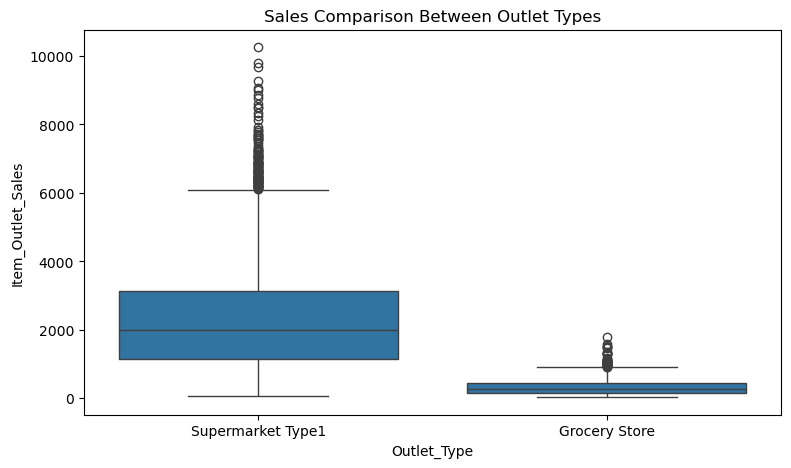

In [44]:
# Visualization

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data[
        data["Outlet_Type"].isin(
            ["Supermarket Type1", "Grocery Store"]
        )
    ],
    x="Outlet_Type",
    y="Item_Outlet_Sales"
)

plt.title("Sales Comparison Between Outlet Types")
plt.show()

### TEST 3: ONE-WAY ANOVA

In [45]:
# Research Question:
# Do average sales differ across outlet types?

# H0: All outlet types have equal mean sales.
# H1: At least one outlet type has different mean sales.

In [46]:
print("\n======================================")
print("TEST 3: ONE-WAY ANOVA")
print("======================================")

groups = [
    group["Item_Outlet_Sales"].values
    for name, group in data.groupby("Outlet_Type")
]

print("\nAverage Sales by Outlet Type:")

print(
    data.groupby("Outlet_Type")["Item_Outlet_Sales"]
    .agg(["count", "mean", "std"]))


TEST 3: ONE-WAY ANOVA

Average Sales by Outlet Type:
                   count         mean          std
Outlet_Type                                       
Grocery Store       1083   339.828500   260.851582
Supermarket Type1   5577  2316.181148  1515.965558
Supermarket Type2    928  1995.498739  1375.932889
Supermarket Type3    935  3694.038558  2127.760054


In [47]:
# Check variance equality

levene_stat, levene_p = levene(*groups)

print("\nLevene Test Statistic:", levene_stat)
print("Levene P-value:", levene_p)


Levene Test Statistic: 430.2565124246685
Levene P-value: 2.7973385000401674e-260


In [48]:
# Welch ANOVA: appropriate when equal variances
# cannot be assumed.

anova_result = anova_oneway(
    groups,
    use_var="unequal"
)

print("\nWelch ANOVA Result:")
print(anova_result)

f_stat = anova_result.statistic
p_value = anova_result.pvalue

print("F-statistic:", f_stat)
print("P-value:", p_value)


Welch ANOVA Result:
statistic = 3684.84860785789
pvalue = 0.0
df = (3.0, np.float64(2239.248939715611))
df_num = 3.0
df_denom = 2239.248939715611
nobs_t = 8523.0
n_groups = 4
means = [ 339.82850046 2316.18114811 1995.49873922 3694.03855765]
nobs = [1083. 5577.  928.  935.]
vars_ = [  68043.54761967 2298151.57162121 1893191.31440726 4527362.84638338]
use_var = unequal
welch_correction = True
tuple = (np.float64(3684.84860785789), np.float64(0.0))
F-statistic: 3684.84860785789
P-value: 0.0


In [49]:
# Effect size: Eta Squared

grand_mean = data["Item_Outlet_Sales"].mean()

ss_between = sum(len(g) * (np.mean(g) - grand_mean) ** 2for g in groups)

ss_total = sum((data["Item_Outlet_Sales"] - grand_mean) ** 2)

eta_squared = ss_between / ss_total

print("Eta Squared:", eta_squared)

Eta Squared: 0.2395752928604761


In [50]:
# Non-parametric sensitivity check

kw_stat, kw_p = kruskal(*groups)

print("\nKruskal-Wallis Test:")
print("Statistic:", kw_stat)
print("P-value:", kw_p)

if p_value < alpha:
    print("Result: Reject Null Hypothesis.")
    print("At least one outlet type has different average sales.")
else:
    print("Result: Fail to Reject Null Hypothesis.")



Kruskal-Wallis Test:
Statistic: 2803.360888346635
P-value: 0.0
Result: Reject Null Hypothesis.
At least one outlet type has different average sales.


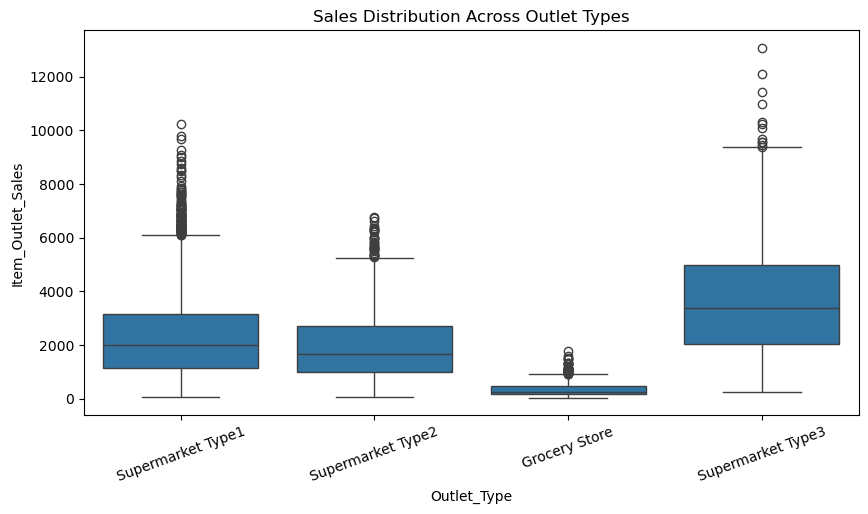

In [51]:
# Visualization

plt.figure(figsize=(10, 5))

sns.boxplot(data=data,x="Outlet_Type",y="Item_Outlet_Sales")

plt.title("Sales Distribution Across Outlet Types")
plt.xticks(rotation=20)
plt.show()

### TEST 4: CHI-SQUARE TEST

In [52]:
# Research Question:
# Is Outlet Location Type associated with Outlet Type?

# H0: Outlet Location Type and Outlet Type are independent.
# H1: They have a significant association.


In [53]:
print("\n======================================")
print("TEST 4: CHI-SQUARE TEST")
print("======================================")

contingency_table = pd.crosstab(
    data["Outlet_Location_Type"],
    data["Outlet_Type"])

print("\nContingency Table:")
print(contingency_table)


TEST 4: CHI-SQUARE TEST

Contingency Table:
Outlet_Type           Grocery Store  Supermarket Type1  Supermarket Type2  \
Outlet_Location_Type                                                        
Tier 1                          528               1860                  0   
Tier 2                            0               2785                  0   
Tier 3                          555                932                928   

Outlet_Type           Supermarket Type3  
Outlet_Location_Type                     
Tier 1                                0  
Tier 2                                0  
Tier 3                              935  


In [54]:
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table)

print("\nChi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

print("\nExpected Frequencies:")
print(pd.DataFrame(expected,index=contingency_table.index,columns=contingency_table.columns))

print("Minimum Expected Frequency:",expected.min())


Chi-Square Statistic: 4725.606588766826
P-value: 0.0
Degrees of Freedom: 6

Expected Frequencies:
Outlet_Type           Grocery Store  Supermarket Type1  Supermarket Type2  \
Outlet_Location_Type                                                        
Tier 1                   303.438226        1562.580781         260.009856   
Tier 2                   353.884196        1822.356565         303.235950   
Tier 3                   425.677578        2192.062654         364.754195   

Outlet_Type           Supermarket Type3  
Outlet_Location_Type                     
Tier 1                       261.971137  
Tier 2                       305.523290  
Tier 3                       367.505573  
Minimum Expected Frequency: 260.0098556846181


In [55]:
# Cramer's V effect size

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * (min(contingency_table.shape) - 1)))

print("Cramer's V:", cramers_v)

if p_value < alpha:
    print("Result: Reject Null Hypothesis.")
    print("There is a significant association.")
else:
    print("Result: Fail to Reject Null Hypothesis.")
    print("There is no significant association.")

Cramer's V: 0.5265232333773107
Result: Reject Null Hypothesis.
There is a significant association.


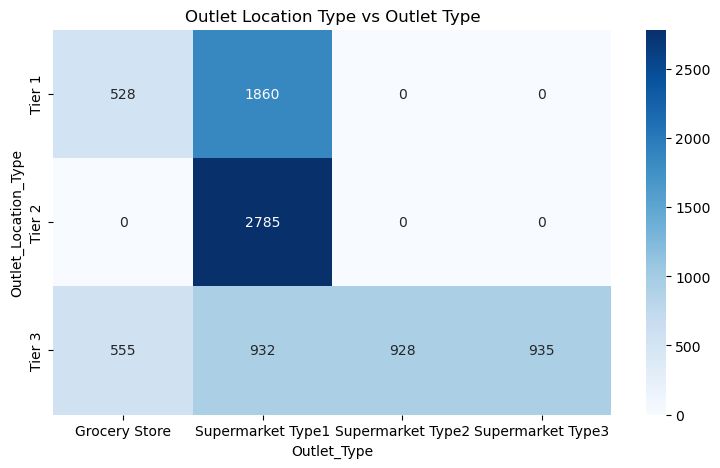

In [56]:
# Visualization

plt.figure(figsize=(9, 5))

sns.heatmap(contingency_table,annot=True,fmt="d",cmap="Blues")

plt.title("Outlet Location Type vs Outlet Type")
plt.show()

### TEST 5: MULTIPLE LINEAR REGRESSION

In [57]:
# Research Question:
# Do Item MRP, Item Visibility, Item Weight,
# Item Type and Outlet Type help explain sales?

# H0: All predictor coefficients are zero.
# H1: At least one predictor coefficient is non-zero.

In [58]:
print("\n======================================")
print("TEST 5: MULTIPLE LINEAR REGRESSION")
print("======================================")

reg_data = data[
    [
        "Item_Outlet_Sales",
        "Item_MRP",
        "Item_Visibility",
        "Item_Weight",
        "Item_Type",
        "Outlet_Type"
    ]
].copy()


TEST 5: MULTIPLE LINEAR REGRESSION


In [59]:
# Handle missing values for regression

reg_data["Item_Weight"] = reg_data[
    "Item_Weight"
].fillna(reg_data["Item_Weight"].median())

reg_data = reg_data.dropna()

In [60]:
# Build regression model

model = smf.ols(
    formula=(
        "Item_Outlet_Sales ~ Item_MRP "
        "+ Item_Visibility + Item_Weight "
        "+ C(Item_Type) + C(Outlet_Type)"
    ),
    data=reg_data
).fit(cov_type="HC3")

In [61]:
print("\nRegression Summary:")
print(model.summary())


Regression Summary:
                            OLS Regression Results                            
Dep. Variable:      Item_Outlet_Sales   R-squared:                       0.562
Model:                            OLS   Adj. R-squared:                  0.561
Method:                 Least Squares   F-statistic:                     397.6
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:23:22   Log-Likelihood:                -72000.
No. Observations:                8523   AIC:                         1.440e+05
Df Residuals:                    8501   BIC:                         1.442e+05
Df Model:                          21                                         
Covariance Type:                  HC3                                         
                                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------

In [62]:
print("\nR-Squared:", model.rsquared)


R-Squared: 0.5624889197838709


In [63]:
print("Adjusted R-Squared:", model.rsquared_adj)

Adjusted R-Squared: 0.5614081372071695


In [64]:
print("Overall F-test P-value:", model.f_pvalue)

Overall F-test P-value: 0.0


In [65]:
print("\nRegression Coefficients:")
print(model.params)


Regression Coefficients:
Intercept                               -1796.716892
C(Item_Type)[T.Breads]                      0.786158
C(Item_Type)[T.Breakfast]                  15.366849
C(Item_Type)[T.Canned]                     25.944833
C(Item_Type)[T.Dairy]                     -43.889525
C(Item_Type)[T.Frozen Foods]              -26.395967
C(Item_Type)[T.Fruits and Vegetables]      29.217643
C(Item_Type)[T.Hard Drinks]               -21.014006
C(Item_Type)[T.Health and Hygiene]        -30.547533
C(Item_Type)[T.Household]                 -58.926762
C(Item_Type)[T.Meat]                        6.818308
C(Item_Type)[T.Others]                    -44.610363
C(Item_Type)[T.Seafood]                   180.488645
C(Item_Type)[T.Snack Foods]               -12.096235
C(Item_Type)[T.Soft Drinks]               -39.872632
C(Item_Type)[T.Starchy Foods]              22.858850
C(Outlet_Type)[T.Supermarket Type1]      1949.297475
C(Outlet_Type)[T.Supermarket Type2]      1620.675058
C(Outlet_Type)[T.Sup

In [66]:
print("\nCoefficient P-values:")
print(model.pvalues)


Coefficient P-values:
Intercept                                1.665472e-153
C(Item_Type)[T.Breads]                    9.920374e-01
C(Item_Type)[T.Breakfast]                 9.031177e-01
C(Item_Type)[T.Canned]                    6.520129e-01
C(Item_Type)[T.Dairy]                     4.796210e-01
C(Item_Type)[T.Frozen Foods]              6.279147e-01
C(Item_Type)[T.Fruits and Vegetables]     5.732488e-01
C(Item_Type)[T.Hard Drinks]               8.020843e-01
C(Item_Type)[T.Health and Hygiene]        6.113443e-01
C(Item_Type)[T.Household]                 2.868305e-01
C(Item_Type)[T.Meat]                      9.178857e-01
C(Item_Type)[T.Others]                    5.896761e-01
C(Item_Type)[T.Seafood]                   2.846319e-01
C(Item_Type)[T.Snack Foods]               8.175408e-01
C(Item_Type)[T.Soft Drinks]               5.527133e-01
C(Item_Type)[T.Starchy Foods]             8.359323e-01
C(Outlet_Type)[T.Supermarket Type1]       0.000000e+00
C(Outlet_Type)[T.Supermarket Type2]      2

In [67]:
print("\n95% Confidence Intervals:")
print(model.conf_int())


95% Confidence Intervals:
                                                 0            1
Intercept                             -1930.144375 -1663.289409
C(Item_Type)[T.Breads]                 -153.609330   155.181646
C(Item_Type)[T.Breakfast]              -232.065775   262.799473
C(Item_Type)[T.Canned]                  -86.814810   138.704477
C(Item_Type)[T.Dairy]                  -165.576326    77.797277
C(Item_Type)[T.Frozen Foods]           -133.140319    80.348385
C(Item_Type)[T.Fruits and Vegetables]   -72.447973   130.883259
C(Item_Type)[T.Hard Drinks]            -185.333183   143.305171
C(Item_Type)[T.Health and Hygiene]     -148.369861    87.274795
C(Item_Type)[T.Household]              -167.361931    49.508406
C(Item_Type)[T.Meat]                   -122.803195   136.439811
C(Item_Type)[T.Others]                 -206.735016   117.514290
C(Item_Type)[T.Seafood]                -150.128627   511.105916
C(Item_Type)[T.Snack Foods]            -114.858480    90.666011
C(Item_Type)[

In [68]:
if model.f_pvalue < alpha:
    print("Result: Reject Null Hypothesis.")
    print("The regression model is statistically significant.")
else:
    print("Result: Fail to Reject Null Hypothesis.")
    print("The regression model is not statistically significant.")

Result: Reject Null Hypothesis.
The regression model is statistically significant.


### REGRESSION DIAGNOSTICS

In [69]:
print("\n======================================")
print("REGRESSION DIAGNOSTICS")
print("======================================")

residuals = model.resid

predicted = model.fittedvalues

# Breusch-Pagan test for heteroscedasticity

bp_test = het_breuschpagan(
    residuals,
    model.model.exog
)

print("\nBreusch-Pagan Test:")
print("LM Statistic:", bp_test[0])
print("P-value:", bp_test[1])

if bp_test[1] < alpha:
    print("Heteroscedasticity may be present.")
else:
    print("No significant evidence of heteroscedasticity.")


REGRESSION DIAGNOSTICS

Breusch-Pagan Test:
LM Statistic: 1220.4595632048179
P-value: 2.4844295345314032e-245
Heteroscedasticity may be present.


In [70]:
# Durbin-Watson statistic

dw = sm.stats.stattools.durbin_watson(residuals)

print("\nDurbin-Watson Statistic:", dw)


Durbin-Watson Statistic: 2.0030165630345804


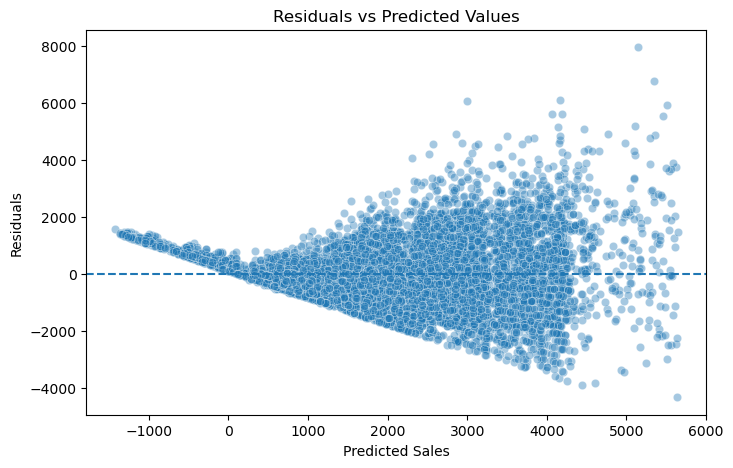

In [71]:
# Residual plot

plt.figure(figsize=(8, 5))

sns.scatterplot(x=predicted,y=residuals,alpha=0.4)

plt.axhline(y=0,linestyle="--")

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.title("Residuals vs Predicted Values")
plt.show()

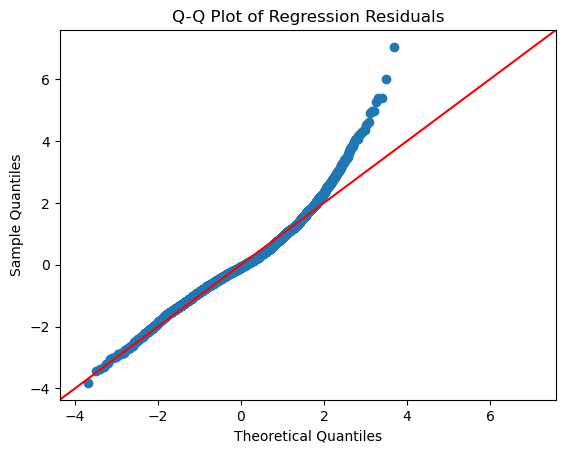

In [72]:
# Q-Q plot

sm.qqplot(residuals,line="45",fit=True)

plt.title("Q-Q Plot of Regression Residuals")
plt.show()

### MULTIPLE HYPOTHESIS TESTING CORRECTION

In [73]:
print("\n======================================")
print("MULTIPLE TESTING CORRECTION")
print("======================================")

test_names = ["Pearson Correlation","Welch T-Test","Welch ANOVA","Chi-Square","Regression"]

p_values = [
    pearsonr(
        data["Item_MRP"],
        data["Item_Outlet_Sales"]
    )[1],
   ttest_ind(group1,group2,equal_var=False).pvalue,anova_result.pvalue,chi2_contingency(contingency_table)[1],model.f_pvalue]

reject, adjusted_p, _, _ = multipletests(p_values,alpha=alpha,method="holm")
results = pd.DataFrame({"Statistical Test": test_names,"Original P-value": p_values,"Adjusted P-value": adjusted_p,"Significant": reject})

print(results)



MULTIPLE TESTING CORRECTION
      Statistical Test  Original P-value  Adjusted P-value  Significant
0  Pearson Correlation               0.0               0.0         True
1         Welch T-Test               0.0               0.0         True
2          Welch ANOVA               0.0               0.0         True
3           Chi-Square               0.0               0.0         True
4           Regression               0.0               0.0         True


### FINAL HYPOTHESIS TEST SUMMARY

In [74]:
print("\n======================================")
print("FINAL HYPOTHESIS TEST SUMMARY")
print("======================================")

for name, p in zip(test_names, p_values):

    print("\nTest:", name)
    print("P-value:", p)

    if p < alpha:
        print("Decision: Reject H0")
        print("Conclusion: Statistically significant result.")
    else:
        print("Decision: Fail to Reject H0")
        print("Conclusion: Not statistically significant.")


FINAL HYPOTHESIS TEST SUMMARY

Test: Pearson Correlation
P-value: 0.0
Decision: Reject H0
Conclusion: Statistically significant result.

Test: Welch T-Test
P-value: 0.0
Decision: Reject H0
Conclusion: Statistically significant result.

Test: Welch ANOVA
P-value: 0.0
Decision: Reject H0
Conclusion: Statistically significant result.

Test: Chi-Square
P-value: 0.0
Decision: Reject H0
Conclusion: Statistically significant result.

Test: Regression
P-value: 0.0
Decision: Reject H0
Conclusion: Statistically significant result.


### FINAL CONCLUSION

In [75]:
print("\n======================================")
print("FINAL CONCLUSION")
print("======================================")

print("""
The statistical analysis was performed on the supermarket
sales dataset using Python.

Pearson correlation was used to examine the relationship
between Item MRP and Item Outlet Sales.

Welch's independent samples t-test was used to compare
average sales between Supermarket Type1 and Grocery Store.

Welch's ANOVA was used to investigate sales differences
across different outlet types.

The Chi-Square test was used to examine the association
between outlet location type and outlet type.

Multiple Linear Regression was applied to examine how
product and outlet characteristics explain sales variation.

The p-values were compared with a significance level of 0.05.

Confidence intervals and effect sizes were also calculated
to understand the strength and practical importance
of the statistical findings.

Statistical significance does not prove causation.
The results should be interpreted along with the
business context and dataset limitations.

This analysis provides statistically supported insights
for understanding supermarket sales patterns.
""")

print("\nWEEK 4 STATISTICAL ANALYSIS COMPLETED SUCCESSFULLY!")



FINAL CONCLUSION

The statistical analysis was performed on the supermarket
sales dataset using Python.

Pearson correlation was used to examine the relationship
between Item MRP and Item Outlet Sales.

Welch's independent samples t-test was used to compare
average sales between Supermarket Type1 and Grocery Store.

Welch's ANOVA was used to investigate sales differences
across different outlet types.

The Chi-Square test was used to examine the association
between outlet location type and outlet type.

Multiple Linear Regression was applied to examine how
product and outlet characteristics explain sales variation.

The p-values were compared with a significance level of 0.05.

Confidence intervals and effect sizes were also calculated
to understand the strength and practical importance
of the statistical findings.

Statistical significance does not prove causation.
The results should be interpreted along with the
business context and dataset limitations.

This analysis provides stati